# El modelo *Integrate and Fire*

## Teoría

El modelo *Integrate and Fire* del comportamiento de una neurona viene descripto por dos ingredientes. En primer lugar, la ODE

\begin{eqnarray}
\frac{dV}{dt}
&=&
f(V(t))
\\
&=&
\frac{1}{\tau}
\left(
E-V(t)
+
RI(t)
\right)
\end{eqnarray}

donde:

* $V(t)$ representa el potencial de membrana al tiempo $t$,

* $E\approx -65mV$ representa el potencial de reposo,

* $\tau\approx 10ms$ representa el tiempo de relajación,

* $R\approx 10M\Omega$ representa una resistencia eléctrica, y

* $I(t)\approx 1nA$ representa una corriente/señal de entrada.

En segundo lugar, un mecanismo de disparo definido por

\begin{eqnarray}
V(t) \to E
\end{eqnarray}

cuando

\begin{eqnarray}
V(t) > V_u
\end{eqnarray}

donde:

* $V_u \approx -50mV$ representa un potencial umbral.

Es decir, según el mecanismo de disparo, el potencial de membrana $V(t)$ se resetea a su valor de reposo $E$ si supera cierto valor umbral $V_u$.

## Unidades

* p = pico = $10^{-12}$
* n = nano = $10^{-9}$
* $\mu$ = micro = $10^{-6}$
* m = mili = $10^{-3}$
* ...
* k = kilo = $10^{3}$
* M = Mega = $10^{6}$
* G = Giga = $10^{9}$
* T = Tera = $10^{12}$

### Ley de Ohm

Si $\Omega$ = Ohmio, V = Voltio y A = Amper, entonces

$$ 1\, Ohm = 1 \Omega = \frac{1 V}{1 A} $$

### Ley RC

Si s = segundos y F = Faradios, entonces

$$ 1 s = 1 \Omega \times 1 F $$

### Hertz

Si Hz = Hertz, luego

$$ 1 Hz = \frac{1}{1 s} $$

### Referencias

* https://technologystudent.com/elec1/ohm1.htm

* https://en.wikipedia.org/wiki/Biological_neuron_model#Leaky_integrate-and-fire

* https://compneuro.neuromatch.io/tutorials/W2D3_BiologicalNeuronModels/student/W2D3_Tutorial1.html



## **Ejercicio 1)** Importando librerías

**1)** Importe las librerías `numpy` para operar con arrays, `scipy` para utilizar rutinas de algebra lineal y `matplotlib.pyplot` para graficar.

**2)** Suba el archivo "libreria" `ode.py` que fabricó en el práctico 4), e impórtelo.

In [1]:
# 1.1)
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

In [1]:
# 1.2)
#import ode

def euler(f, x, t, h, p):
    """
    Calcula un paso de integración del método de Euler.

    Argumentos de entrada:

        f : R^n,R -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Euler.

    # Ejemplos:
    """
    return x + h * f(x, t, p)


def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5 * h * k1, t + 0.5 * h, p)
    k3 = f(x + 0.5 * h * k2, t + 0.5 * h, p)
    k4 = f(x + h * k3, t + h, p)
    return x + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
    """
    Integra numéricamente la ODE

        dx/dt = f(x,t)

    sobre el intervalo t:[a,b] usando k pasos de integración y el método m, bajo condicion inicial x(a)=x0.
    No es necesario que a<b.

    Argumentos de entrada:

        m = metodo de integracion (ej. euler, rk2, etc.)
        f : R^n -> R^n
        xa = condicion inicial : R
        a = tiempo inicial : R
        b = tiempo final : R
        k = num. pasos de integracion : N
        p = parametros : R^q
        c = función condicionante : R^n,R,p -> R^n

    Retorna:

        t : R^{k+1} , t_j = a+j*h para j=0,1,...,k
        w : R^{n,k+1} , w_ij = x_i(t_j) para i=0,1,...,n-1 y j=0,1,...,k

    donde a+k*dt = b.
    """
    assert k > 0
    n = len(xa)
    h = (b - a) / k
    w = np.zeros((n, k + 1))  # Produce un array con forma y tipo especificada con los parametros,
    # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k + 1)
    w[:, 0] = xa  # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
    # de las condiciones iniciales
    t[0] = a  # actualiza la posicion cero con el valor del tiempo inicial

    for j in range(k):  #Aca se produce la iteración en j

        t[j + 1] = t[j] + h  # iteracion tiempo
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)  # iteracion de w
        w[:, j + 1] = c(w[:, j + 1], t[j + 1], p)  # condicion sobre w

    return t, w

## **Ejercicio 2)** Dinámica con mecanismo de disparo desactivado

En lo que sigue, se considera desactivado el mecanismo de disparo.

**1)** Resuelva analíticamente la ODE del modelo *Integrate and Fire* para una condición inicial arbitraria $V(0)=V_0$ y una corriente de entrada $I=0$.

**2)** Grafique la solución para $V_0=10mV$ y $t\in [0,100]ms$. Incorpore al gráfico una línea punteada indicando el potencial de reposo.

**3)** Realice un análisis geométrico de la solución calculada. Incorpore flechas del campo vectorial así como los puntos fijos estables, inestables y marginales, si los hubiere.

**4)** Repita **1)**, **2)** y **3)** para el caso de corriente de entrada constante, $I=2$nA.

### Extra

**5)** Resuelva analíticamente la ODE para una corriente de entrada $I:t\to I(t)$ arbitraria.
<img src="../extra/img.png">

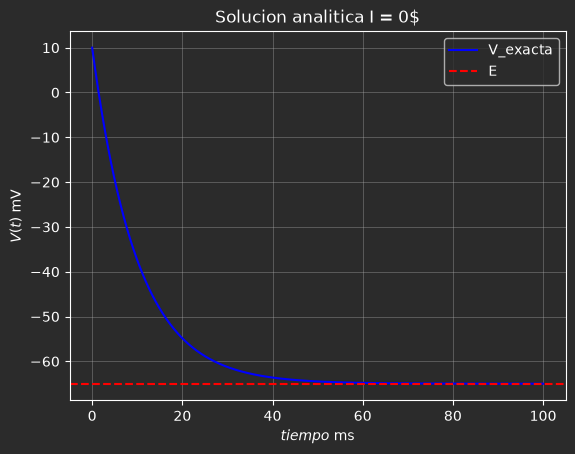

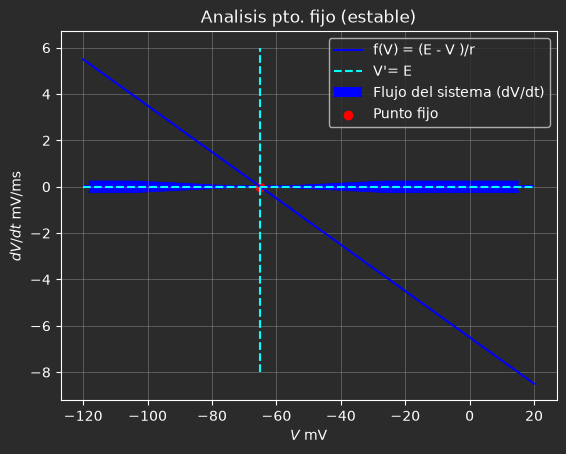

In [3]:
# 2.1)
# https://drive.google.com/file/d/1KfHdH0XmCivd8Mcc7T_u5j5FZnrwU65l/view
# Derivada de una const (como E) es cero 0.
# te queda dV/dt = (E-V)/r
# luego la exacta V(t) = E + (V0 - E)e^(-t/r)

E = -65.0
V0 = 10.0
r = 10.0
t = np.linspace(0.0, 100, 1001)

plt.xlabel('$tiempo$ ms')
plt.ylabel('$V(t)$ mV')
plt.plot(t, E + (V0 - E) * np.exp(-t / r), label="V_exacta", linestyle='-', c='blue')
plt.axhline(E, linestyle='--', color='red', label="E")
plt.title(f"Solucion analitica I = 0$")
plt.legend()
plt.grid()
plt.show()

# f(V) = (E-V)/r
# Pto. fijo ==> f(V') = 0 ==> V' = E = -65mV
# Si V < E el potencial aumenta c.c disminuye

# El punto fijo ocurre cuando dV/dt = 0
# Para determinar qué tipo de punto fijo es, calculamos la derivada de la función f(V) respecto a V: f'(V) = -1/r
# como f'(V_fix) < 0 entonces el punto fijo es estable (Atractor)
# SI FUERA f'(V_fix) > 0 entonces el punto fijo es inestable (Repulsor)
# SI FUERA f'(V_fix) == 0 entonces el punto fijo es marginal (Indeterminado)

V_fix = E
V = np.linspace(-120, 20, 1001)
plt.xlabel('$V$ mV')
plt.ylabel('$dV/dt$ mV/ms')
plt.title("Analisis pto. fijo (estable)")
plt.plot(V, (E - V) / r, label="f(V) = (E - V )/r", linestyle='-', c='blue')
plt.plot(V, V * 0, label="V'= E", linestyle='--', c='cyan')

plt.quiver(V, np.zeros_like(V), (E - V) / r, np.zeros_like(V),
           angles='xy', scale_units='xy', scale=1,
           color='blue', width=0.005, headwidth=5, headlength=5,
           label='Flujo del sistema (dV/dt)')

plt.plot([V_fix, V_fix], [-8, 6], linestyle='--', c='cyan')
plt.scatter([V_fix], (E - V_fix) / r, label="Punto fijo", c='red')
# plt.plot(V, (E - V)/r, label="f(V) = (E - V )/r", linestyle='-', c='blue')

plt.legend()
plt.grid()
plt.show()

#Notar que el grafico con dV/dt y V es un grafico entre x e y.
# Por ejemlpo f(x) = x tiene infinitos puntos fijos
# f(x) = x + 2 no tiene ninguno
# f(x) = x^2 tiene dos puntos fijos

#TODO: podemos pensar esto como en Cinematica en Fisica 1, que tenemos la funcion de velocidad v(t) = dx(t)/dt, pero no tenemos posicion  x(t), y lo podemos sacar integrando v(t) es decir resolviendo la ecuacion asociada a dx(t)/dt.



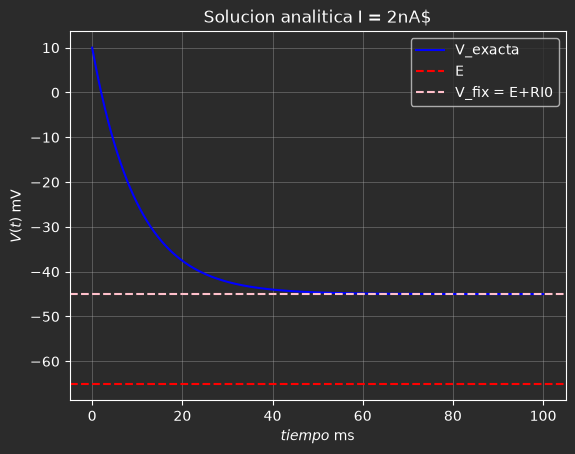

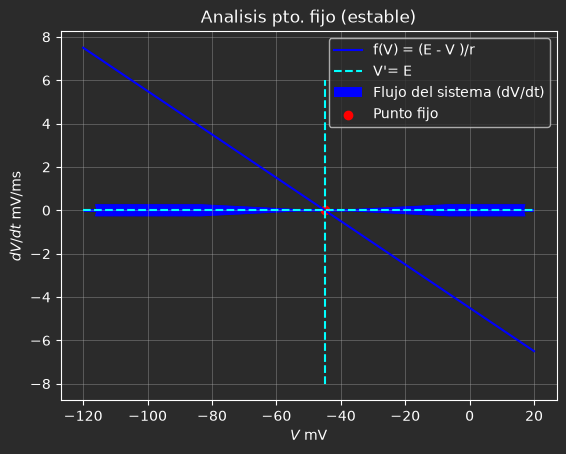

In [4]:
## con corriente const
# dV/dt = (E+RI0-V)/r
# V(t) = V_fix + (V0 - V_fix)e^(-t/r)
# V_fix = E+RI0 = -65mV + 10Mo * 2nA = -45mA

E = -65.0
R = 10
I0 = 2
V_fix = -45
V0 = 10.0
r = 10.0

t = np.linspace(0.0, 100, 1001)

plt.xlabel('$tiempo$ ms')
plt.ylabel('$V(t)$ mV')
plt.plot(t, V_fix + (V0 - V_fix) * np.exp(-t / r), label="V_exacta", linestyle='-', c='blue')
plt.axhline(E, linestyle='--', color='red', label="E")
plt.axhline(V_fix, linestyle='--', color='pink', label="V_fix = E+RI0")
plt.title(f"Solucion analitica I = 2nA$")
plt.legend()
plt.grid()
plt.show()

V = np.linspace(-120, 20, 1001)
plt.xlabel('$V$ mV')
plt.ylabel('$dV/dt$ mV/ms')
plt.title("Analisis pto. fijo (estable)")
plt.plot(V, (V_fix - V) / r, label="f(V) = (E - V )/r", linestyle='-', c='blue')
plt.plot(V, V * 0, label="V'= E", linestyle='--', c='cyan')

plt.quiver(V, np.zeros_like(V), (V_fix - V) / r, np.zeros_like(V),
           angles='xy', scale_units='xy', scale=1,
           color='blue', width=0.005, headwidth=5, headlength=5,
           label='Flujo del sistema (dV/dt)')

plt.plot([V_fix, V_fix], [-8, 6], linestyle='--', c='cyan')
plt.scatter([V_fix], ((E + R * I0) - V_fix) / r, label="Punto fijo", c='red')

plt.legend()
plt.grid()
plt.show()


Partimos de la ODE para $I=0$

bla bla bla ...

Partimos de la ODE para $I=0$

bla bla bla ...

## **Ejercicio 3)** Dinámica con mecanismo de disparo activado

**1)** Resuelva numéricamente la ODE del modelo *Integrate and Fire* en el intervalo $t\in [0,200]ms$ para la condición inicial $V(0)=E$ y una corriente de entrada $I(t)=I_0$ para todo $t$ con $I_0=2nA$. Utilice el paso de integración $h=0.05ms$.

**2)** Grafique la solución computada en el inciso **3.1)**. Incorpore al gráfico la solución exacta del inciso **2.1)** (en donde el mecanismo de disparo está desactivado) para la condición inicial del inciso anterior. Además, grafique líneas punteadas horizontales marcando los valores de $V^*$ y $V_u$, donde $V^*$ es el valor de $V$ tal que $f(V)=0$.

**3)** Para el caso indicado en el inciso **3.1)**, calcule analíticamente el período de disparo. Observe si el valor computado corresponde con el observado en el inciso **3.2)**. Grafíque la frencuencia en función de $I_0$.
Que ocurre para valores pequeños de $I_0$?

**4)** Repita **3.1)** y **3.2)** con $I_e(t)=I_0 \cos(t/30ms)$ e $I_0=2.5nA$ para $0\,ms\leq t\leq 500\,ms$. En este caso, no incluya la solución exacta del inciso **2.1)**, pero sí lineas punteadas horizontales para marcar los valores de $E$ y $V_u$.

**5)** Repita **3.1)** y **3.2)** con

\begin{equation}
I(t)= I_0 \, \left(
    \cos{\left( \frac{t}{3ms} \right)} +
    \sin{\left( \frac{t}{5ms} \right)} +
    \cos{\left( \frac{t}{7ms} \right)} +
    \sin{\left( \frac{t}{11ms} \right)} +
    \cos{\left( \frac{t}{13ms} \right)}  \right)^2 \, nA \,
    \;\;\;(4)
\end{equation}

e $I_0=0.35 nA$ para $0\,ms\leq t\leq 200\,ms$. Al igual que en inciso anterior, no incluya la solución exacta del inciso **2.a)**, pero sí lineas punteadas horizontales para marcar los valores de $E$ y $V_u$.

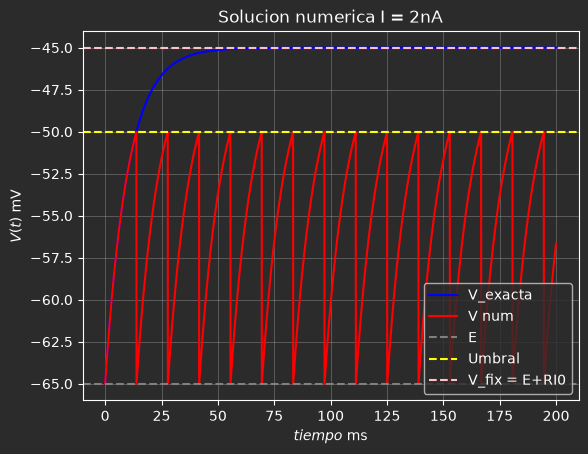

In [5]:
# 3.1)

## con corriente const
# dV/dt = (E+RI0-V)/r
# V(t) = V_fix + (V0 - V_fix)e^(-t/r)
# V_fix = E+RI0 = -65mV + 10Mo * 2nA = -45mA

E = -65.0
R = 10
I0 = 2
V_fix = -45
V0 = E
r = 10.0
Vu = -50.0

p = np.array([E, R, I0, r, Vu])


def f(x, t, p):
    E = p[0]
    R = p[1]
    I0 = p[2]
    r = p[3]
    V_fix = E + R * I0
    return (V_fix - np.array(x[0])) / r


def trigger(v, t, p):
    Vu = p[4]
    E = p[0]
    if v > Vu:
        return E
    else:
        return v


a = 0
b = 200
h = 0.05
k = int((b - a) / h)

t, w = integrador_ode(rk4, f, np.array([V0]), a, b, k, p, trigger)

plt.xlabel('$tiempo$ ms')
plt.ylabel('$V(t)$ mV')
plt.plot(t, V_fix + (V0 - V_fix) * np.exp(-t / r), label="V_exacta", linestyle='-', c='blue')
plt.plot(t, w[0, :], label="V num", linestyle='-', c='red')
plt.axhline(E, linestyle='--', color='grey', label="E")
plt.axhline(Vu, linestyle='--', color='yellow', label="Umbral")
plt.axhline(V_fix, linestyle='--', color='pink', label="V_fix = E+RI0")
plt.title(f"Solucion numerica I = 2nA")
plt.legend()
plt.grid()
plt.show()


14
14.285714285714286


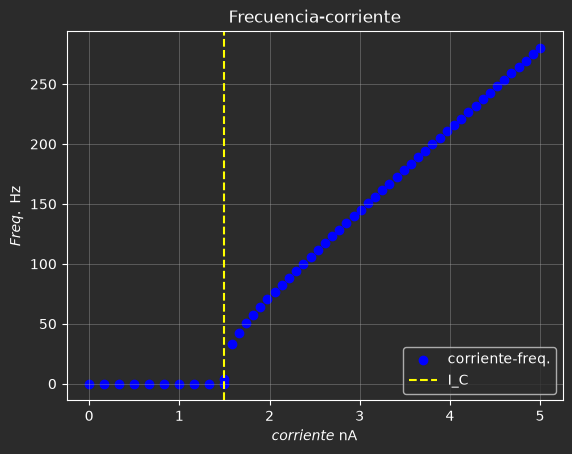

In [6]:
# El periodo satisface Vu = E + RI0(1-e^(-T/r))
# despejando T = -rln(1- (Vu-E)/(RI0))
# Tambien hay corriente critica Ic = (Vu - E0) /R (te queda ln(0)) por debajo del cual no hay disparos
# Ic = 1.5nA (nunca sobrepasa umbral)
# Para I0 = 2nA T = 13.863ms
# Frequencia es 1/T (Hertz) 1000/T(ms) --> 72.13 Hz

hits = []
for i in range(len(w[0, :])):
    v_i = w[0, :][i]
    if rk4(f, np.array([v_i]), t[i], h, p) > Vu:
        hits.append((round(float(t[i]), 2), round(float(v_i), 2)))
# print(hits)
print(len(hits))

# si hago b = 2000 con h = 0.02 ==> el periodo me da 13.8888889, con b = 20000 tiende a 13.90ms
print((b - a) / len(hits))

T = -r * np.log(1 - ((Vu - E) / (R * I0)))
fre = 1 / T
I_c = (Vu - E) / R
I = np.linspace(I_c + 1e-10, 5, 45)
I_minor = np.linspace(0, I_c - 1e-10, 10)

plt.xlabel('$corriente$ nA')
plt.ylabel('$Freq.$ Hz')
plt.scatter(I_minor, I_minor * 0, color='blue')
plt.scatter(I, 1000 / (-r * np.log(1 - ((Vu - E) / (R * I)))), label="corriente-freq.", linestyle='-', c='blue')
# plt.axhline(Vu, linestyle='--', color='yellow', label="Umbral")
plt.axvline(I_c, linestyle='--', color='yellow', label="I_C")
plt.title(f"Frecuencia-corriente")
plt.legend()
plt.grid()
plt.show()


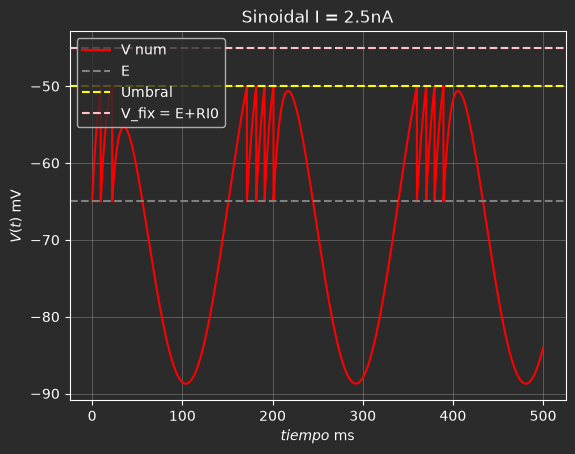

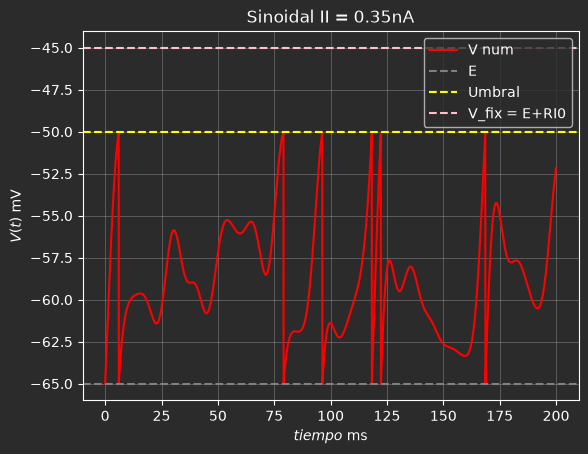

In [7]:
E = -65.0
R = 10
I0 = 2.5
V_fix = -45
V0 = E
r = 10.0
Vu = -50.0


def I_cos(t):
    return I0 * np.cos(t / 30.0)


# dV/dt = (E+RI0-V)/r
# V(t) = V_fix + (V0 - V_fix)e^(-t/r)
# V_fix = E+RI0 = -65mV + 10Mo * 2nA = -45mA


p = np.array([E, R, I0, r, Vu])


def f(x, t, p):
    E = p[0]
    R = p[1]
    I0 = p[2]
    r = p[3]
    V_fix = E + R * I_cos(t)
    return (V_fix - np.array(x[0])) / r


a = 0
b = 500
h = 0.05
k = int((b - a) / h)

t, w = integrador_ode(rk4, f, np.array([V0]), a, b, k, p, trigger)

plt.xlabel('$tiempo$ ms')
plt.ylabel('$V(t)$ mV')
plt.plot(t, w[0, :], label="V num", linestyle='-', c='red')
plt.axhline(E, linestyle='--', color='grey', label="E")
plt.axhline(Vu, linestyle='--', color='yellow', label="Umbral")
plt.axhline(V_fix, linestyle='--', color='pink', label="V_fix = E+RI0")
plt.title(f"Sinoidal I = 2.5nA")
plt.legend()
plt.grid()
plt.show()

I0 = 0.35


def I_cos_2(t):
    return I0 * np.pow(np.cos(t / 3) + np.sin(t / 5) + np.cos(t / 7) + np.sin(t / 11) + np.cos(t / 13), 2)


def f2(x, t, p):
    E = p[0]
    R = p[1]
    I0 = p[2]
    r = p[3]
    V_fix = E + R * I_cos_2(t)
    return (V_fix - np.array(x[0])) / r


a = 0
b = 200
h = 0.05
k = int((b - a) / h)

t, w = integrador_ode(rk4, f2, np.array([V0]), a, b, k, p, trigger)

plt.xlabel('$tiempo$ ms')
plt.ylabel('$V(t)$ mV')
plt.plot(t, w[0, :], label="V num", linestyle='-', c='red')
plt.axhline(E, linestyle='--', color='grey', label="E")
plt.axhline(Vu, linestyle='--', color='yellow', label="Umbral")
plt.axhline(V_fix, linestyle='--', color='pink', label="V_fix = E+RI0")
plt.title(f"Sinoidal II = 0.35nA")
plt.legend()
plt.grid()
plt.show()


